# 📱 Smart Device Advisor
## مستشار الأجهزة الذكية

في هذا المشروع نقوم ببناء نظام ذكاء اصطناعي لتحليل بيانات الأجهزة الذكية، ودراسة مواصفاتها وأسعارها وتقييماتها، ثم استخدام البيانات لتقديم توصيات مناسبة للمستخدم بناءً على الميزانية والتقييم وخصائص الجهاز.

## 1. تعريف المشروع

هدف المشروع هو تحليل بيانات الأجهزة الذكية وبناء نموذج يتوقع السعر التقريبي اعتمادًا على النص الوصفي للمواصفات والتقييم، بالإضافة إلى نظام توصية يعرض أفضل الأجهزة المناسبة للمستخدم.

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

pd.set_option("display.max_columns", None)


## 2. تحميل مجموعة البيانات

In [2]:
csv_files = glob.glob("../data/*.csv")

if not csv_files:
    raise FileNotFoundError("لم يتم العثور على أي ملف CSV داخل مجلد data")

mobile_files = [
    f for f in csv_files
    if any(word in os.path.basename(f).lower()
           for word in ["mobile", "device", "recommend"])
]

file_path = mobile_files[0] if mobile_files else csv_files[0]

print("Dataset selected:", file_path)

df = pd.read_csv(file_path)
display(df.head())


Dataset selected: ../data\mobile_recommendation_system_dataset.csv


,name,ratings,price,imgURL,corpus
0,"REDMI Note 12 Pro 5G (Onyx Black, 128 GB)",4.2,23999,https://rukminim2.flixcart.com/image/312/312/x...,Storage128 GBRAM6 SystemAndroid 12Processor T...
1,"OPPO F11 Pro (Aurora Green, 128 GB)",4.5,"₹20,999",https://rukminim2.flixcart.com/image/312/312/k...,Storage128 GBRAM6 GBExpandable Storage256GB S...
2,"REDMI Note 11 (Starburst White, 64 GB)",4.2,13149,https://rukminim2.flixcart.com/image/312/312/x...,Storage64 GBRAM4 SystemAndroid 11Processor Sp...
3,"OnePlus Nord CE 5G (Blue Void, 256 GB)",4.1,21999,https://rukminim2.flixcart.com/image/312/312/x...,Storage256 GBRAM12 SystemAndroid Q 11Processo...
4,"APPLE iPhone 13 mini (Blue, 128 GB)",4.6,3537,https://rukminim2.flixcart.com/image/312/312/k...,Storage128 SystemiOS 15Processor TypeA15 Bion...


## 3. فهم البيانات

In [3]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (2546, 5)

Columns:
['name', 'ratings', 'price', 'imgURL', 'corpus']

Data types:
name           str
ratings    float64
price          str
imgURL         str
corpus         str
dtype: object

Missing values:


,Missing Values
corpus,12
name,0
ratings,0
price,0
imgURL,0



Duplicate rows: 1


## 4. تنظيف البيانات

هنا نعالج القيم المفقودة والصفوف المكررة ونحوّل السعر فقط إلى رقم. **لا نقوم بتحويل اسم الجهاز أو النص الوصفي إلى أرقام**، لأن وجود أرقام داخل اسم مثل `REDMI Note 12 Pro 5G` لا يعني أن الاسم متغير رقمي.

In [4]:
df = df.drop_duplicates().copy()

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

# تحديد الأعمدة الأصلية
name_col = next(
    (c for c in df.columns if c.lower() in ["name", "model", "device_name"]),
    None
)

price_col = next(
    (c for c in df.columns if "price" in c.lower() or "cost" in c.lower()),
    None
)

rating_col = next(
    (c for c in df.columns if "rating" in c.lower() or "ratings" in c.lower() or "score" in c.lower()),
    None
)

corpus_col = next(
    (c for c in df.columns if "corpus" in c.lower() or "description" in c.lower() or "spec" in c.lower()),
    None
)

if price_col is None:
    raise ValueError("لم يتم العثور على عمود السعر.")

# تنظيف السعر فقط وتحويله إلى رقم
df[price_col] = (
    df[price_col]
    .astype(str)
    .str.replace(r"[^0-9.]", "", regex=True)
)

df[price_col] = pd.to_numeric(df[price_col], errors="coerce")

# تحويل التقييم إلى رقم إن وجد
if rating_col is not None:
    df[rating_col] = pd.to_numeric(df[rating_col], errors="coerce")

# معالجة القيم المفقودة
if name_col is not None:
    df[name_col] = df[name_col].fillna("Unknown Device").astype(str)

if corpus_col is not None:
    df[corpus_col] = df[corpus_col].fillna("").astype(str)

if rating_col is not None:
    df[rating_col] = df[rating_col].fillna(df[rating_col].median())

df = df.dropna(subset=[price_col]).copy()

print("Device name column:", name_col)
print("Price column:", price_col)
print("Rating column:", rating_col)
print("Corpus column:", corpus_col)
print("Dataset shape after cleaning:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Device name column: name
Price column: price
Rating column: ratings
Corpus column: corpus
Dataset shape after cleaning: (2545, 5)
Remaining missing values: 0
Duplicate rows: 0


## 5. التحليل الاستكشافي للبيانات (EDA)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,2545,2134,"OPPO Reno10 5G (Ice Blue, 256 GB)",13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ratings,2545.0,NaN,NaN,NaN,4.295835,0.214725,2.9,4.2,4.3,4.4,5.0
price,2545.0,NaN,NaN,NaN,16918.954028,8632.068285,73.0,10499.0,15499.0,23463.0,89999.0
imgURL,2545,1674,https://rukminim2.flixcart.com/image/312/312/x...,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
corpus,2545,1604,,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Numeric columns: ['ratings', 'price']


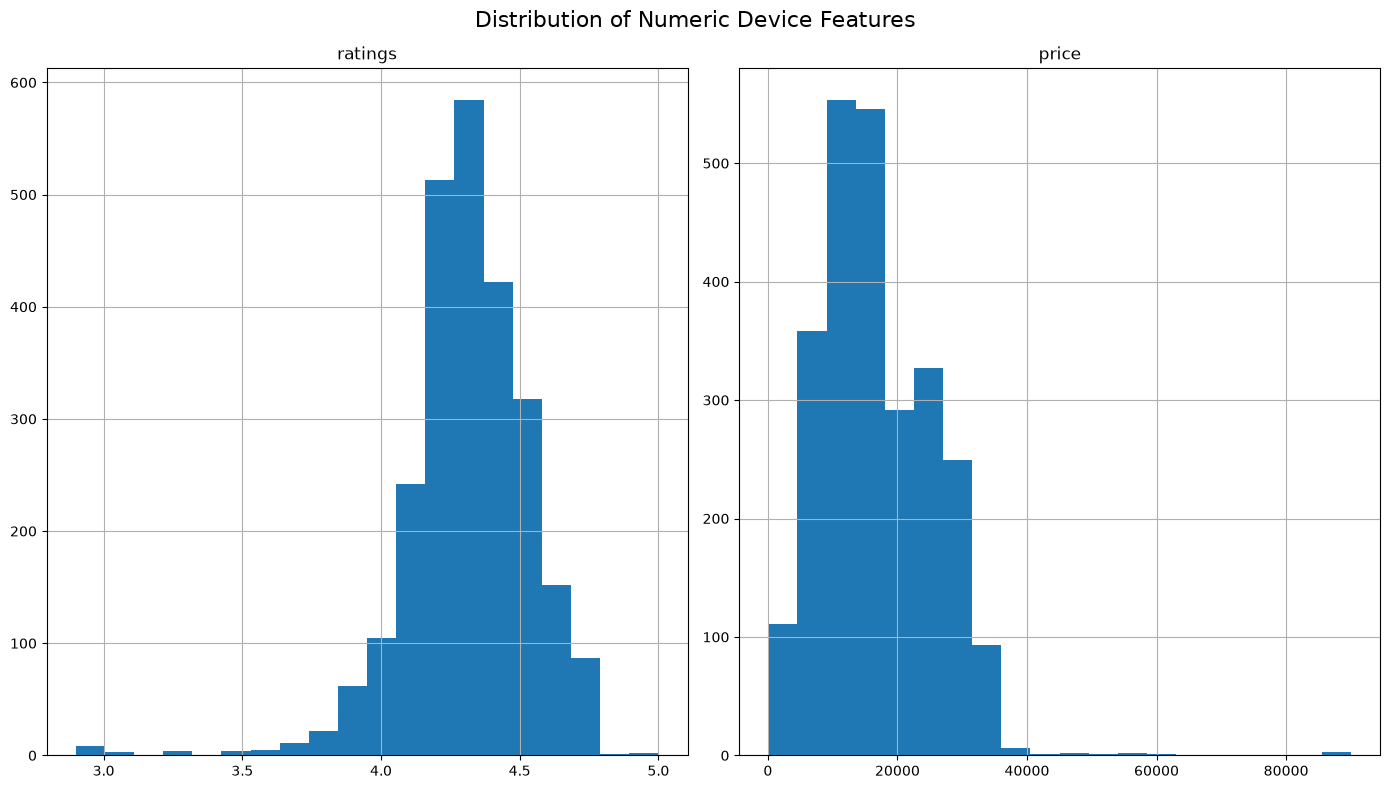

In [5]:
display(df.describe(include="all").T)

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_columns)

if numeric_columns:
    df[numeric_columns].hist(figsize=(14, 8), bins=20)
    plt.suptitle("Distribution of Numeric Device Features", fontsize=16)
    plt.tight_layout()
    plt.show()


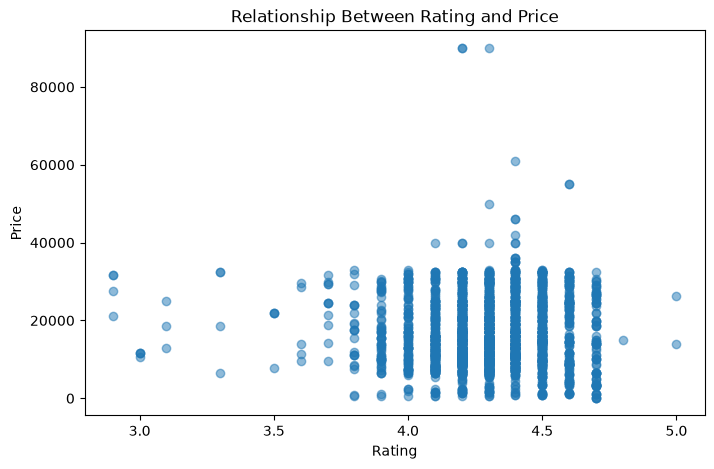

In [6]:
if rating_col is not None:
    plt.figure(figsize=(8, 5))
    plt.scatter(df[rating_col], df[price_col], alpha=0.5)
    plt.xlabel("Rating")
    plt.ylabel("Price")
    plt.title("Relationship Between Rating and Price")
    plt.show()


## 6. اختيار المتغير المستهدف

In [7]:
target_column = price_col

print("Selected target:", target_column)


Selected target: price


## 7. تجهيز البيانات

سنستخدم:
- النص المجمع من **اسم الجهاز + مواصفاته**.
- تقييم الجهاز إن وجد.

بهذه الطريقة نحافظ على أسماء الأجهزة كنصوص، ونتجنب الخطأ السابق الناتج عن استخراج أرقام من اسم الجهاز.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

text_series = pd.Series("", index=df.index, dtype="object")

if name_col is not None:
    text_series = text_series + df[name_col].fillna("").astype(str) + " "

if corpus_col is not None:
    text_series = text_series + df[corpus_col].fillna("").astype(str)

model_df = pd.DataFrame({
    "text_features": text_series,
    "rating": df[rating_col] if rating_col is not None else 0.0
})

y = df[target_column].copy()

X_train, X_test, y_train, y_test = train_test_split(
    model_df,
    y,
    test_size=0.20,
    random_state=42
)

print("Features shape:", model_df.shape)
print("Target shape:", y.shape)
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)


Features shape: (2545, 2)
Target shape: (2545,)
Training Features: (2036, 2)
Testing Features: (509, 2)


## 8. تدريب نموذجين

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(
                max_features=3000,
                ngram_range=(1, 2),
                stop_words="english"
            ),
            "text_features"
        ),
        (
            "rating",
            StandardScaler(),
            ["rating"]
        )
    ]
)

model_ridge = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=10.0))
    ]
)

model_rf = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                min_samples_leaf=2,
                n_jobs=-1
            )
        )
    ]
)

model_ridge.fit(X_train, y_train)
model_rf.fit(X_train, y_train)

print("Both models trained successfully!")


Both models trained successfully!


## 9. مقارنة النماذج

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_ridge = model_ridge.predict(X_test)
pred_rf = model_rf.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Ridge Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, pred_ridge),
        mean_absolute_error(y_test, pred_rf)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred_ridge)),
        np.sqrt(mean_squared_error(y_test, pred_rf))
    ],
    "R2 Score": [
        r2_score(y_test, pred_ridge),
        r2_score(y_test, pred_rf)
    ]
})

comparison = comparison.sort_values("R2 Score", ascending=False)
display(comparison)


,Model,MAE,RMSE,R2 Score
1,Random Forest,2357.206158,3820.607413,0.770452
0,Ridge Regression,3672.677392,5030.503121,0.602048


## 10. اختيار أفضل نموذج

In [11]:
best_model_name = comparison.iloc[0]["Model"]

best_model = (
    model_ridge
    if best_model_name == "Ridge Regression"
    else model_rf
)

print("Best Model:", best_model_name)


Best Model: Random Forest


## 11. التقييم

In [12]:
best_predictions = best_model.predict(X_test)

mae = mean_absolute_error(y_test, best_predictions)
rmse = np.sqrt(mean_squared_error(y_test, best_predictions))
r2 = r2_score(y_test, best_predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)


MAE: 2357.206158312109
RMSE: 3820.607412567538
R² Score: 0.7704521763333831


## 12. التنبؤ ببيانات جهاز جديدة

In [13]:
sample_device = pd.DataFrame({
    "text_features": [
        "REDMI Note 12 Pro 5G 128GB 6GB RAM Android 12 Snapdragon AMOLED"
    ],
    "rating": [4.2]
})

prediction = best_model.predict(sample_device)[0]

print("Predicted Price:", round(prediction, 2))


Predicted Price: 13305.92


## 13. توصية الأجهزة المناسبة

هذه الخدمة تستخدم بيانات الأجهزة الفعلية مباشرة لاختيار أفضل الأجهزة ضمن ميزانية المستخدم، ثم ترتب النتائج حسب التقييم من الأعلى إلى الأقل.

In [14]:
def recommend_devices(data, budget, min_rating=0, top_n=5):
    recommendations = data.copy()

    recommendations = recommendations[
        recommendations[price_col] <= budget
    ]

    if rating_col is not None:
        recommendations = recommendations[
            recommendations[rating_col] >= min_rating
        ]

    sort_columns = []
    ascending = []

    if rating_col is not None:
        sort_columns.append(rating_col)
        ascending.append(False)

    sort_columns.append(price_col)
    ascending.append(True)

    recommendations = recommendations.sort_values(
        by=sort_columns,
        ascending=ascending
    )

    columns_to_show = [
        c for c in [name_col, rating_col, price_col]
        if c is not None
    ]

    return recommendations[columns_to_show].head(top_n)

user_budget = 50000
min_user_rating = 4.0

recommended_devices = recommend_devices(
    df,
    budget=user_budget,
    min_rating=min_user_rating,
    top_n=5
)

print("Top recommended devices:")
display(recommended_devices)


Top recommended devices:


,name,ratings,price
692,"Tecno Camon 19 Neo (Ice Mirror, 6 GB)",5.0,13995
1151,"APPLE iPhone 12 Pro Max (Pacific Blue, 256 GB)",5.0,26273
489,"SAMSUNG Galaxy A12 (Blue, 128 GB)",4.8,14999
43,"APPLE iPhone 14 Pro (Gold, 256 GB)",4.7,73
974,"APPLE iPhone 14 Pro (Silver, 256 GB)",4.7,73


## 14. حفظ النموذج

In [15]:
model_path = "../models/smart_device_advisor_model.pkl"
os.makedirs("../models", exist_ok=True)

joblib.dump(
    {
        "model": best_model,
        "model_name": best_model_name,
        "target_column": target_column,
        "input_columns": ["text_features", "rating"],
        "name_column": name_col,
        "price_column": price_col,
        "rating_column": rating_col
    },
    model_path
)

print("Model saved successfully!")
print("Saved at:", model_path)


Model saved successfully!
Saved at: ../models/smart_device_advisor_model.pkl


## 15. اختبار النموذج المحفوظ

In [16]:
saved_data = joblib.load("../models/smart_device_advisor_model.pkl")
saved_model = saved_data["model"]

test_device = pd.DataFrame({
    "text_features": [
        "REDMI Note 12 Pro 5G 128GB 6GB RAM Android 12 Snapdragon AMOLED"
    ],
    "rating": [4.2]
})

saved_prediction = saved_model.predict(test_device)[0]

print("Saved model loaded successfully!")
print("Predicted Price from saved model:", round(saved_prediction, 2))
print("Model used:", saved_data["model_name"])


Saved model loaded successfully!
Predicted Price from saved model: 13305.92
Model used: Random Forest
